# 06 · Report card and the money

**What this notebook does, in plain words**

1. **The money.** Notebook 03 found that, within the same grade, borrowers with some job titles really defaulted more or less often. Here we turn those gaps into dollars: if a lender priced a loan to match each title's *real* risk, how much more or less interest would a borrower pay?
2. **The report card.** One table grading every "loan officer" we tested (LendingClub's grade, our model, Gemini with two prompts; Gemma was attempted but couldn't be completed) on the same three questions: can it rank risk, does it react to job titles, and does that reaction match reality?

Nothing here calls an AI. It only reads results saved by notebooks 02 to 05.

## Setup

Loads the clean loans, the real gaps from notebook 03, and the saved results from notebooks 02, 04 and 05.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

SEED = 2015
PREREGISTERED = [
    "software engineer", "police officer", "executive assistant", "attorney", "teacher",
    "registered nurse", "mechanic", "president", "general manager", "owner", "truck driver", "server",
]
SUBGRADE_ORDER = [f"{g}{n}" for g in "ABCDEFG" for n in range(1, 6)]

loans = pd.read_parquet("data/loans_clean.parquet")
real = pd.read_csv("outputs/real_gaps.csv", index_col="condition")
loans_2015 = loans[loans["year"] == 2015]
print(f"{len(loans_2015):,} finished 36-month loans issued in 2015")

283,026 finished 36-month loans issued in 2015


## Step 1 · Each sub-grade's 2015 default rate and interest rate

For every sub-grade (A1 to G5): how often its 2015 loans defaulted, and its average interest rate. Sub-grades with fewer than 200 loans in 2015 are left out, because their default rates are too noisy to match against.

In [2]:
MIN_LOANS = 200
subgrades = (loans_2015.groupby("sub_grade")
             .agg(loans=("default", "size"), default_rate=("default", "mean"), interest_rate=("int_rate", "mean"))
             .reindex(SUBGRADE_ORDER).dropna())
subgrades = subgrades[subgrades["loans"] >= MIN_LOANS]
print(f"{len(subgrades)} sub-grades with at least {MIN_LOANS} loans in 2015")
subgrades.assign(default_rate=lambda d: (d["default_rate"] * 100).round(1), interest_rate=lambda d: d["interest_rate"].round(2))

28 sub-grades with at least 200 loans in 2015


,loans,default_rate,interest_rate
sub_grade,,,
A1,12372,2.7,5.46
A2,11526,3.9,6.31
A3,10888,5.0,6.86
A4,14924,6.2,7.20
A5,20408,7.6,7.92
B1,17746,9.0,8.24
B2,18278,10.5,9.20
B3,18513,11.8,10.01
B4,18069,13.0,10.99


## Step 2 · Turn each title's real gap into a price

Take a **typical C1 borrower** (the middle of LendingClub's range). For each title:

1. **Shift the risk.** Add the title's real gap to C1's 2015 default rate. For example, if C1 loans defaulted 17% of the time and truck drivers defaulted 4.7 points more than their grade predicted, a C1 truck driver's real risk is about 21.7%.
2. **Find the matching grade.** Pick the sub-grade whose 2015 default rate is closest to that shifted risk.
3. **Read off its price.** Take that sub-grade's average 2015 interest rate.
4. **Count the interest.** Work out the total interest on a **\$10,000, 36-month loan** at that rate, using the standard fixed monthly payment, and compare it with C1's.

The result is **what a price matching real risk would be**. It is not what these borrowers actually paid: LendingClub never saw the gap, so everyone in C1 paid C1's rate.

**One limit:** prices move in steps from one sub-grade to the next. A title with a small gap can land on C1 itself and show \$0.

In [3]:
LOAN, MONTHS, START = 10_000, 36, "C1"

def total_interest(annual_rate_pct, principal=LOAN, months=MONTHS):
    r = annual_rate_pct / 100 / 12
    payment = principal * r / (1 - (1 + r) ** -months)
    return payment * months - principal

c1_rate = subgrades.loc[START, "default_rate"]
c1_interest = total_interest(subgrades.loc[START, "interest_rate"])
print(f"C1 in 2015: {c1_rate:.1%} defaulted, average rate {subgrades.loc[START, 'interest_rate']:.2f}%, "
      f"total interest on ${LOAN:,} over {MONTHS} months = ${c1_interest:,.0f}")

rows = []
for title in PREREGISTERED:
    gap = real.loc[title, "real_gap_pp"]
    target = c1_rate + gap / 100
    match = (subgrades["default_rate"] - target).abs().idxmin()
    rate = subgrades.loc[match, "interest_rate"]
    rows.append({"title": title, "real_gap_pp": gap, "risk_if_C1_pct": target * 100, "matching_subgrade": match,
                 "interest_rate_pct": rate, "total_interest": total_interest(rate),
                 "vs_C1_dollars": total_interest(rate) - c1_interest})
money = pd.DataFrame(rows).set_index("title").sort_values("real_gap_pp")
money.to_csv("outputs/money_by_title.csv")
money.round(2)

C1 in 2015: 17.0% defaulted, average rate 12.25%, total interest on $10,000 over 36 months = $1,999


,real_gap_pp,risk_if_C1_pct,matching_subgrade,interest_rate_pct,total_interest,vs_C1_dollars
title,,,,,,
software engineer,-5.82,11.15,B2,9.20,1481.29,-518.07
police officer,-3.65,13.32,B4,10.99,1784.29,-215.07
executive assistant,-3.38,13.59,B4,10.99,1784.29,-215.07
attorney,-3.15,13.82,B4,10.99,1784.29,-215.07
teacher,-2.15,14.82,B5,11.55,1879.21,-120.15
registered nurse,-0.99,15.98,C1,12.25,1999.36,0.00
mechanic,-0.20,16.77,C1,12.25,1999.36,0.00
president,0.16,17.13,C1,12.25,1999.36,0.00
general manager,2.45,19.42,C3,13.34,2189.01,189.65


## In one line per title

What a price matching real risk would be, for a typical C1 borrower borrowing \$10,000 over 36 months.

In [4]:
for title, r in money.iterrows():
    if r["matching_subgrade"] == START:
        line = f"same as C1 (gap too small to change the grade)"
    else:
        direction = "less" if r["vs_C1_dollars"] < 0 else "more"
        line = f"priced like {r['matching_subgrade']} at {r['interest_rate_pct']:.1f}%: ${abs(r['vs_C1_dollars']):,.0f} {direction} interest than C1"
    print(f"{title:20s} real gap {r['real_gap_pp']:+.1f} pts -> {line}")

software engineer    real gap -5.8 pts -> priced like B2 at 9.2%: $518 less interest than C1
police officer       real gap -3.6 pts -> priced like B4 at 11.0%: $215 less interest than C1
executive assistant  real gap -3.4 pts -> priced like B4 at 11.0%: $215 less interest than C1
attorney             real gap -3.1 pts -> priced like B4 at 11.0%: $215 less interest than C1
teacher              real gap -2.1 pts -> priced like B5 at 11.5%: $120 less interest than C1
registered nurse     real gap -1.0 pts -> same as C1 (gap too small to change the grade)
mechanic             real gap -0.2 pts -> same as C1 (gap too small to change the grade)
president            real gap +0.2 pts -> same as C1 (gap too small to change the grade)
general manager      real gap +2.5 pts -> priced like C3 at 13.3%: $190 more interest than C1
owner                real gap +2.8 pts -> priced like C3 at 13.3%: $190 more interest than C1
truck driver         real gap +4.7 pts -> priced like C4 at 14.0%: $299 more

## Chart · What a price matching real risk would be

One bar per title: how much more (orange) or less (blue) total interest a typical C1 borrower would pay if the price matched their job title's real risk. The label shows the sub-grade they'd be priced like.

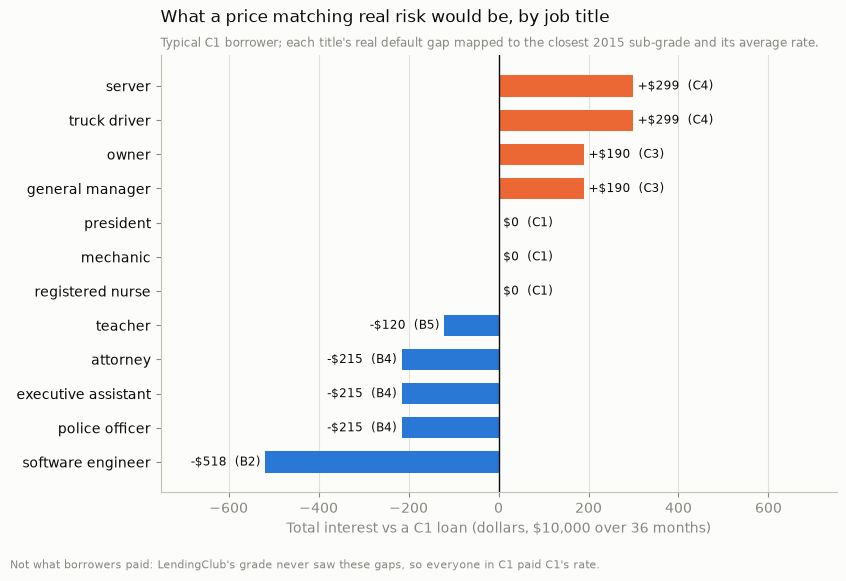

In [5]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

plot = money.sort_values("real_gap_pp")
y = np.arange(len(plot))
colors = [ORANGE if v > 0 else BLUE for v in plot["vs_C1_dollars"]]

fig, ax = plt.subplots(figsize=(8.5, 5.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.barh(y, plot["vs_C1_dollars"], color=colors, height=0.62)
ax.axvline(0, color=INK, linewidth=1)
span = plot["vs_C1_dollars"].abs().max()
for yi, (title, r) in zip(y, plot.iterrows()):
    v = r["vs_C1_dollars"]
    text = f"{'+' if v > 0 else '-' if v < 0 else ''}${abs(v):,.0f}  ({r['matching_subgrade']})"
    ax.text(v + (span * 0.02 if v >= 0 else -span * 0.02), yi, text, va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=INK)
ax.set_yticks(y, plot.index)
ax.set_xlim(-span * 1.45, span * 1.45)
ax.set_xlabel(f"Total interest vs a C1 loan (dollars, ${LOAN:,} over {MONTHS} months)", color=MUTED)
ax.set_title("What a price matching real risk would be, by job title", loc="left", color=INK, fontsize=12, pad=24)
ax.text(0, 1.02, f"Typical C1 borrower; each title's real default gap mapped to the closest 2015 sub-grade and its average rate.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["bottom", "left"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors=MUTED)
for label in ax.get_yticklabels():
    label.set_color(INK)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.text(0.01, 0.01, "Not what borrowers paid: LendingClub's grade never saw these gaps, so everyone in C1 paid C1's rate.",
         color=MUTED, fontsize=8)
Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/money_by_title.png", dpi=200)
plt.show()

## Step 3 · Our model's job-title pattern

Our model never sees job titles. But it does see income, debt and credit history, which differ between jobs, so it might pick up some of the job pattern indirectly.

To check, for each title we take the 2015 loans and compare the model's average predicted risk with the grade's prediction (that sub-grade's 2015 default rate). If the model's title-by-title differences rank the titles the way reality does, it is capturing the pattern without being told the job.

The model predicts too little risk for 2015 overall, which shifts every title up by about the same amount. A rank correlation ignores that shift.

In [6]:
scored = pd.read_parquet("data/test_2015_scored.parquet")
scored["title"] = scored["job_title"].fillna("(blank)")
scored["grade_expected"] = scored.groupby("sub_grade")["default"].transform("mean")
model_pattern = (scored[scored["title"].isin(PREREGISTERED)]
                 .assign(diff=lambda d: (d["model_risk"] - d["grade_expected"]) * 100)
                 .groupby("title")["diff"].mean().reindex(PREREGISTERED))

x_real = real.loc[PREREGISTERED, "real_gap_pp"].to_numpy()
def rank_corr_with_interval(values, n_boot=2_000, seed=SEED):
    v = np.asarray(values, dtype=float)
    rho = stats.spearmanr(x_real, v).statistic
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(v), len(v))
        if len(np.unique(x_real[i])) >= 3:
            boots.append(stats.spearmanr(x_real[i], v[i]).statistic)
    return rho, np.nanpercentile(boots, 2.5), np.nanpercentile(boots, 97.5)

model_rho = rank_corr_with_interval(model_pattern)
print(f"Our model's title pattern vs reality: rank correlation {model_rho[0]:+.2f} "
      f"(95% interval {model_rho[1]:+.2f} to {model_rho[2]:+.2f}, resampling titles)")
pd.DataFrame({"model_minus_grade_pts": model_pattern, "real_gap_pts": real.loc[PREREGISTERED, "real_gap_pp"]}).sort_values("real_gap_pts").round(2)

Our model's title pattern vs reality: rank correlation +0.20 (95% interval -0.59 to +0.78, resampling titles)


,model_minus_grade_pts,real_gap_pts
software engineer,-2.74,-5.82
police officer,-2.33,-3.65
executive assistant,-1.76,-3.38
attorney,-0.86,-3.15
teacher,-1.38,-2.15
registered nurse,-1.79,-0.99
mechanic,-2.72,-0.20
president,-2.44,0.16
general manager,-1.66,2.45
owner,-1.92,2.83


## Step 4 · A simple-rule baseline: FICO score alone

The simplest risk rule a lender could use is to rank applicants by credit score: lower FICO, riskier. Any AI or model worth using should beat it.

- **All 2015 loans:** AUC of FICO alone, next to LendingClub's sub-grade and our model (from notebook 02).
- **The 500 check loans** from the competence check (notebook 04): Gemini against FICO on exactly the same loans, with a **paired bootstrap** (2,000 resamples) for the difference.

In [7]:
from sklearn.metrics import roc_auc_score

y15 = scored["default"].to_numpy()
fico_risk = -scored["fico"].to_numpy()                    # lower FICO = riskier
fico_auc_all = roc_auc_score(y15, fico_risk)
rng = np.random.default_rng(SEED)
fico_boot = []
for _ in range(200):                                      # 283,026 loans: 200 resamples give a stable interval
    i = rng.integers(0, len(y15), len(y15))
    fico_boot.append(roc_auc_score(y15[i], fico_risk[i]))
auc_all_2015 = pd.read_csv("outputs/auc_results.csv", index_col=0).iloc[:, 0]
print(f"All {len(y15):,} 2015 loans: FICO alone {fico_auc_all:.3f} ({np.percentile(fico_boot, 2.5):.3f} to "
      f"{np.percentile(fico_boot, 97.5):.3f}); sub-grade {auc_all_2015['LendingClub sub-grade (baseline)']:.3f}; "
      f"our model {auc_all_2015['Gradient boosting']:.3f}")

check = pd.read_csv("outputs/competence_scores.csv", dtype={"id": str}).merge(scored[["id", "fico"]], on="id", how="left")
assert check["fico"].notna().all() and len(check) == 500
SUBGRADE_RANK = {s: i for i, s in enumerate(SUBGRADE_ORDER)}
yc = check["default"].to_numpy()
rankers = {"Gemini (plain prompt, no job title)": check["ai_probability"].to_numpy(),
           "FICO score alone": -check["fico"].to_numpy(),
           "LendingClub sub-grade": check["sub_grade"].map(SUBGRADE_RANK).to_numpy()}
pt = {k: roc_auc_score(yc, v) for k, v in rankers.items()}
rng = np.random.default_rng(SEED)
bt = {k: [] for k in rankers}
for _ in range(2_000):
    i = rng.integers(0, len(yc), len(yc))
    if yc[i].min() == yc[i].max():
        continue
    for k, v in rankers.items():
        bt[k].append(roc_auc_score(yc[i], v[i]))
bt = {k: np.array(v) for k, v in bt.items()}
rows = [{"ranker": k, "loans": "500 check loans", "AUC": pt[k], "low": np.percentile(bt[k], 2.5), "high": np.percentile(bt[k], 97.5)}
        for k in rankers]
for a, b in [("Gemini (plain prompt, no job title)", "FICO score alone"), ("LendingClub sub-grade", "FICO score alone")]:
    d = bt[a] - bt[b]
    rows.append({"ranker": f"{a} minus {b}", "loans": "500 check loans", "AUC": pt[a] - pt[b],
                 "low": np.percentile(d, 2.5), "high": np.percentile(d, 97.5)})
rows.append({"ranker": "FICO score alone", "loans": f"all {len(y15):,} 2015 loans", "AUC": fico_auc_all,
             "low": np.percentile(fico_boot, 2.5), "high": np.percentile(fico_boot, 97.5)})
fico_table = pd.DataFrame(rows).set_index("ranker")
fico_table.round(4).to_csv("outputs/fico_baseline.csv")
fico_table.round(3)

All 283,026 2015 loans: FICO alone 0.601 (0.599 to 0.604); sub-grade 0.679; our model 0.669


,loans,AUC,low,high
ranker,,,,
"Gemini (plain prompt, no job title)",500 check loans,0.625,0.553,0.696
FICO score alone,500 check loans,0.579,0.507,0.644
LendingClub sub-grade,500 check loans,0.657,0.589,0.728
"Gemini (plain prompt, no job title) minus FICO score alone",500 check loans,0.047,-0.004,0.100
LendingClub sub-grade minus FICO score alone,500 check loans,0.079,0.008,0.156
FICO score alone,"all 283,026 2015 loans",0.601,0.599,0.604


## Step 5 · Does "Is my rate fair?" hold up on real loans?

The demo's "Is my rate fair?" tab places a borrower in the sub-grade their risk deserves. It uses our model's risk, ranked against all 2015 loans, with the rank-based cutoffs from notebook 02 (`outputs/deserved_subgrade_cutoffs.csv`). Here we check that placement against what really happened on the 2015 loans.

For each loan we count **how many sub-grades the model's placement differs from the real one**. Negative means the model says the borrower deserved a *better* (safer) grade than LendingClub gave them; positive means *worse*. Then we compare each group's **actual default rate** with the rate **their real sub-grade predicted** (that sub-grade's 2015 default rate).

If the placement is meaningful, borrowers the model moves to a better grade should default **less** than their grade predicted, and those it moves to a worse grade should default **more**.

One limit: the app's job-title adjustment isn't included, because it applies to only 12 titles. This checks the model part.

In [8]:
cut = pd.read_csv("outputs/deserved_subgrade_cutoffs.csv", index_col=0)
assert list(cut.index) == SUBGRADE_ORDER and cut["risk_up_to"].is_monotonic_increasing
idx = np.minimum(np.searchsorted(cut["risk_up_to"].to_numpy(), scored["model_risk"].to_numpy(), side="left"), len(cut) - 1)
v = scored[["default", "sub_grade", "model_risk"]].copy()
v["deserved"] = cut.index[idx]
v["steps"] = v["deserved"].map(SUBGRADE_RANK) - v["sub_grade"].map(SUBGRADE_RANK)
v["grade_predicted"] = v.groupby("sub_grade")["default"].transform("mean")      # the real sub-grade's 2015 default rate

labels = ["5+ grades better", "3-4 better", "1-2 better", "same sub-grade", "1-2 worse", "3-4 worse", "5+ grades worse"]
s_ = v["steps"]
v["placement"] = np.select(
    [s_ <= -5, s_.between(-4, -3), s_.between(-2, -1), s_ == 0, s_.between(1, 2), s_.between(3, 4), s_ >= 5], labels, default="?")

validation = v.groupby("placement", observed=True).agg(
    loans=("default", "size"), actual_default_pct=("default", "mean"), grade_predicted_pct=("grade_predicted", "mean"))
validation[["actual_default_pct", "grade_predicted_pct"]] *= 100
validation["difference_pts"] = validation["actual_default_pct"] - validation["grade_predicted_pct"]
validation["share_of_loans_pct"] = validation["loans"] / len(v) * 100
validation = validation.reindex(labels)
validation.round(2).to_csv("outputs/rate_fairness_validation.csv")
print("Negative difference = defaulted less than their real grade predicted.")
validation.round(1)

Negative difference = defaulted less than their real grade predicted.


,loans,actual_default_pct,grade_predicted_pct,difference_pts,share_of_loans_pct
placement,,,,,
5+ grades better,45723,18.8,23.4,-4.5,16.2
3-4 better,33291,14.8,17.2,-2.4,11.8
1-2 better,46793,12.9,14.1,-1.2,16.5
same sub-grade,29413,11.2,11.5,-0.3,10.4
1-2 worse,46808,13.5,12.3,1.3,16.5
3-4 worse,34754,14.6,12.2,2.4,12.3
5+ grades worse,46244,16.9,12.5,4.5,16.3


## Step 6 · The report card

One row per loan officer, graded on three questions:

- **Ranks risk:** AUC (0.5 = coin flip, 1.0 = perfect). "All 2015 loans" comes from notebook 02. "500 check loans" comes from the competence check in notebook 04: the same 500 loans for everyone, job title left blank for Gemini.
- **Reacts to job titles:** the largest change in the AI's estimate caused by the job title alone, and the permutation p-value for whether titles matter at all (notebook 05).
- **Matches reality's job pattern:** rank correlation between how the officer treats the 12 titles and how they really repaid (+1 same order, 0 no link, −1 reversed), with its 95% interval. With only 12 titles these intervals are wide.

The verdicts follow simple, stated rules: titles "matter" if the permutation p is below 0.05, and a rank correlation counts as following reality above +0.3 or against it below −0.3. Rows that couldn't be measured say so.

**Gemma 4 31B is listed but not graded.** Its run was stopped after Google's servers failed repeatedly (notebook 04), with only 9 of 23 batches scored. Keeping the row shows the check was attempted.

In [9]:
def fmt_auc(auc, low=None, high=None):
    if auc is None or pd.isna(auc):
        return "not measured"
    return f"{auc:.3f}" + (f" ({low:.3f} to {high:.3f})" if low is not None else "")

auc_all = pd.read_csv("outputs/auc_results.csv", index_col=0).iloc[:, 0]
comp_path = Path("outputs/competence_auc.csv")
comp = pd.read_csv(comp_path, index_col=0) if comp_path.exists() else None
robust = pd.read_csv("outputs/robustness.csv", index_col=0)

def comp_auc(name):
    if comp is None or name not in comp.index:
        return "not measured"
    return fmt_auc(comp.loc[name, "auc"], comp.loc[name, "low"], comp.loc[name, "high"])

def ai_row(label, variant, comp_name=None, unavailable=None):
    if variant not in robust.index:
        status = "not available" if unavailable else "pending"
        return {"loan officer": label, "AUC, all 2015 loans": "not measured", "AUC, 500 check loans": "not measured",
                "largest title effect": status, "titles matter? (permutation p)": status,
                "rank corr. with reality": status, "verdict": unavailable or "Run not finished yet."}
    r = robust.loc[variant]
    matters = r["permutation_p"] < 0.05
    rho = r["rank_corr"]
    pattern = "follows reality" if rho > 0.3 else "goes against reality" if rho < -0.3 else "has no clear link to reality"
    if matters:
        verdict = f"Reacts to job titles, and its pattern {pattern}."
    else:
        verdict = (f"Largely ignores job titles (largest effect {float(r['largest_effect']):.1f} pts): "
                   f"no stereotyping, but it misses a real gap of up to about 5 pts.")
    return {"loan officer": label, "AUC, all 2015 loans": "not measured",
            "AUC, 500 check loans": comp_auc(comp_name) if comp_name else "not measured",
            "largest title effect": f"{float(r['largest_effect']):.2f} pts ({r['largest_effect_title']})",
            "titles matter? (permutation p)": f"{'yes' if matters else 'no'} (p = {float(r['permutation_p']):.3f})",
            "rank corr. with reality": f"{rho:+.2f} ({float(r['rank_low']):+.2f} to {float(r['rank_high']):+.2f})",
            "verdict": verdict}

card = pd.DataFrame([
    {"loan officer": "LendingClub sub-grade", "AUC, all 2015 loans": fmt_auc(auc_all["LendingClub sub-grade (baseline)"]),
     "AUC, 500 check loans": comp_auc("LendingClub sub-grade"),
     "largest title effect": "not tested (black box)", "titles matter? (permutation p)": "not tested",
     "rank corr. with reality": "n/a: the real gaps are measured against it",
     "verdict": "Best at ranking risk overall, but within a grade, job titles still differ by up to about 5 pts in real default."},
    {"loan officer": "Our model (notebook 02)", "AUC, all 2015 loans": fmt_auc(auc_all["Gradient boosting"]),
     "AUC, 500 check loans": comp_auc("Our model (notebook 02)"),
     "largest title effect": "0 by design (never sees titles)", "titles matter? (permutation p)": "no (by design)",
     "rank corr. with reality": f"{model_rho[0]:+.2f} ({model_rho[1]:+.2f} to {model_rho[2]:+.2f}), indirectly via other fields",
     "verdict": "Slightly behind the grade overall but adds within-grade signal. "
                + ("Picks up part of the job pattern through other fields." if model_rho[1] > 0
                   else "Shows no clear sign of picking up the job pattern through other fields (interval includes 0).")},
    ai_row("Gemini 3.5 Flash-Lite, plain prompt", "plain (main_1 + main_2)", "Gemini (plain prompt, no job title)"),
    ai_row("Gemini 3.5 Flash-Lite, loan-officer persona", "persona"),
    ai_row("Gemma 4 31B, plain prompt", "gemma",
           unavailable="Not graded: Google's servers kept failing, so only 9 of 23 batches were scored (notebook 04)."),
]).set_index("loan officer")
card.to_csv("outputs/report_card.csv")
with pd.option_context("display.max_colwidth", None):
    display(card)

,"AUC, all 2015 loans","AUC, 500 check loans",largest title effect,titles matter? (permutation p),rank corr. with reality,verdict
loan officer,,,,,,
LendingClub sub-grade,0.679,0.657 (0.589 to 0.728),not tested (black box),not tested,n/a: the real gaps are measured against it,"Best at ranking risk overall, but within a grade, job titles still differ by up to about 5 pts in real default."
Our model (notebook 02),0.669,0.684 (0.608 to 0.754),0 by design (never sees titles),no (by design),"+0.20 (-0.59 to +0.78), indirectly via other fields",Slightly behind the grade overall but adds within-grade signal. Shows no clear sign of picking up the job pattern through other fields (interval includes 0).
"Gemini 3.5 Flash-Lite, plain prompt",not measured,0.625 (0.553 to 0.696),0.81 pts (president),no (p = 0.067),+0.00 (-0.57 to +0.63),"Largely ignores job titles (largest effect 0.8 pts): no stereotyping, but it misses a real gap of up to about 5 pts."
"Gemini 3.5 Flash-Lite, loan-officer persona",not measured,not measured,0.81 pts (president),no (p = 0.183),-0.33 (-0.89 to +0.43),"Largely ignores job titles (largest effect 0.8 pts): no stereotyping, but it misses a real gap of up to about 5 pts."
"Gemma 4 31B, plain prompt",not measured,not measured,not available,not available,not available,"Not graded: Google's servers kept failing, so only 9 of 23 batches were scored (notebook 04)."
